# Evolución transversal del haz y fusión de los máximos de fluencia

**Análisis de los seis T-Track XY de PHITS — irradiación con protones**

**Pregunta:** ¿cómo evoluciona la depresión central generada por el oclusor y a qué posición longitudinal $z$ desaparecen matemáticamente los dos máximos laterales?

Este notebook sigue un recorrido reproducible:

1. Leer las seis matrices de fluencia $\Phi(x,y;z_i)$.
2. Extraer y visualizar los perfiles transversales en $X$ e $Y$.
3. Ajustar cada perfil posterior al oclusor mediante dos gaussianas simétricas.
4. Obtener los parámetros $a(z_i)$ y $\sigma(z_i)$.
5. Interpolarlos en $z$ y buscar la condición de transición $a(z_*)=\sigma(z_*)$.
6. Contrastar esa estimación con los perfiles originales y con un criterio práctico de depresión menor al 5 %.

**Importante:** la altura de transición que resulte del modelo solo es confiable si la suma de dos gaussianas reproduce bien los datos simulados. La posición del pouch más conveniente requiere también estudiar la homogeneidad bidimensional y la dosis en el medio real.

## 1. Datos disponibles: ¿qué mide cada T-Track?

Cada archivo contiene una matriz transversal a una altura conocida:

$$\Phi_i(x,y)=\Phi(x,y;z_i).$$

No hace falta una tally continua en $z$. La dependencia longitudinal se obtiene **comparando la forma del perfil en distintas alturas**.

| Posición $z_i$ [cm] | Archivo | Interpretación |
|---:|---|---|
| 33,94 | `track_xy_antes_oclusor.out` | Referencia antes del segundo dispersor/oclusor |
| 45,00 | `track_xy_despues_oclusor.out` | Sombra central inmediatamente después |
| 66,80 | `track_xy_entre_oc_y_pouch.out` | Solapamiento parcial |
| 80,00 | `track_xy_antes_pouch.out` | Depresión más suave |
| 98,48 | `track_xy_pouch.out` | Altura original del pouch |
| 100,96 | `track_xy_piso.out` | Próximo al piso del montaje |

Se comparan **tallies en aire**, con igual geometría, energía de partida y normalización. Los archivos del estudio previo con agua no deben mezclarse en un mismo ajuste longitudinal.

El perfil anterior al oclusor se visualizará como referencia, pero **no** se ajustará con el modelo de dos gaussianas, pues ese modelo representa la sombra creada por el oclusor.

## 2. Importar bibliotecas e indicar los archivos

La carpeta está definida como `../out`, igual que en el código que veníamos usando. Si tu notebook está en otra ubicación, cambiá solamente la variable `carpeta`.

Para los ajustes se utiliza `scipy.optimize.curve_fit`; para interpolar con suavidad, `PchipInterpolator`; y para localizar las raíces, `brentq`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from pathlib import Path
from scipy.optimize import curve_fit, brentq
from scipy.interpolate import PchipInterpolator
from IPython.display import display

carpeta = Path("..") / "out"

archivos = [
    (33.94, "track_xy_antes_oclusor.out"),
    (45.00, "track_xy_despues_oclusor.out"),
    (66.80, "track_xy_entre_oc_y_pouch.out"),
    (80.00, "track_xy_antes_pouch.out"),
    (98.48, "track_xy_pouch.out"),
    (100.96, "track_xy_piso.out"),
]

xmin, xmax, xdel = -10, 10, 0.3
ymin, ymax, ydel = -15, 15, 0.3

print("Directorio de lectura:", carpeta.resolve())

Directorio de lectura: C:\Users\Jessica Riback\Desktop\Labo 6y7 Basili-Rodriguez\Labo 7\ridgefilter\perfil_haz\out


## 3. Leer los archivos de PHITS y recuperar los perfiles

La función busca las dimensiones `nx`, `ny` y el encabezado `hc:` del archivo de salida. Luego construye la matriz de fluencia y las coordenadas de los centros de los bins.

La malla usada en PHITS tiene aproximadamente $\Delta x=\Delta y=0{,}3\,\mathrm{cm}$. El perfil por el origen se extrae con la fila más cercana a $y=0$ y la columna más cercana a $x=0$:

$$\Phi_x(x;z_i)=\Phi(x,0;z_i),\qquad \Phi_y(y;z_i)=\Phi(0,y;z_i).$$

**Nota técnica:** se invierte el orden de las filas en `y`, como en el lector anterior, para interpretar el orden vertical de la matriz exportada por PHITS. Si el mapa obtenido no coincide con los ejes del EPS original, hay que verificar esta convención antes de seguir.

In [2]:
def leer_ttrack(filename):
    with open(filename, "r", errors="replace") as f:
        lines = f.readlines()

    nx = ny = inicio = None

    for i, line in enumerate(lines):
        if "nx =" in line and "ny =" in line:
            mx = re.search(r"\bnx\s*=\s*(\d+)", line)
            my = re.search(r"\bny\s*=\s*(\d+)", line)
            if mx and my:
                nx = int(mx.group(1))
                ny = int(my.group(1))
        if line.strip().startswith("hc:") and inicio is None:
            inicio = i + 1

    if nx is None or ny is None or inicio is None:
        raise ValueError(f"No se pudieron leer nx, ny o hc: de {filename}")

    patron = r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[EeDd][-+]?\d+)?"
    datos = []

    for line in lines[inicio:]:
        if line.strip().startswith("#"):
            break
        for numero in re.findall(patron, line):
            datos.append(float(numero.replace("D", "E").replace("d", "e")))
        if len(datos) >= nx * ny:
            break

    datos = np.asarray(datos[:nx * ny], dtype=float)

    if datos.size != nx * ny:
        raise ValueError(f"{filename}: se esperaban {nx * ny} valores y se leyeron {datos.size}")

    flujo = datos.reshape(ny, nx)[::-1, :]
    return flujo, nx, ny


resultados = []

for z, nombre in archivos:
    flujo, nx, ny = leer_ttrack(carpeta / nombre)
    x = xmin + (np.arange(nx) + 0.5) * xdel
    y = ymin + (np.arange(ny) + 0.5) * ydel
    ix0 = int(np.argmin(np.abs(x)))
    iy0 = int(np.argmin(np.abs(y)))
    px = flujo[iy0, :]
    py = flujo[:, ix0]

    resultados.append({
        "z": z,
        "archivo": nombre,
        "flujo": flujo,
        "x": x,
        "y": y,
        "perfil_x": px,
        "perfil_y": py,
        "r_x": float(px[ix0] / np.max(px)),
        "r_y": float(py[iy0] / np.max(py)),
        "centro_x": float(x[ix0]),
        "centro_y": float(y[iy0])
    })

print(f"Se leyeron {len(resultados)} mapas XY")
print(f"Centro del bin de X: {resultados[0]['centro_x']:.3f} cm")
print(f"Centro del bin de Y: {resultados[0]['centro_y']:.3f} cm")

Se leyeron 6 mapas XY
Centro del bin de X: 0.050 cm
Centro del bin de Y: 0.150 cm


## 4. Primera medida sin ajustes: profundidad de la depresión central

Antes de introducir gaussianas podemos calcular directamente de cada perfil:

$$R_x(z)=\frac{\Phi_x(0;z)}{\max_x\Phi_x(x;z)}, \qquad R_y(z)=\frac{\Phi_y(0;z)}{\max_y\Phi_y(y;z)}.$$

La depresión relativa es

$$D(z)=100\,[1-R(z)]\;\%.$$

Por ejemplo, en la simulación en aire a $z=98{,}48\,\mathrm{cm}$ obtuvimos aproximadamente $R_x=0{,}967$: la depresión es cercana al **3,3 %**.

**Esto NO prueba que ya desaparecieron los dos máximos.** Un perfil puede conservar un mínimo central muy poco profundo y, por lo tanto, seguir siendo bimodal aunque $R$ sea cercano a 1.

,z [cm],R X,R Y,Depresión X [%],Depresión Y [%]
0,33.94,0.934,1.000,6.576,0.000
1,45.00,0.069,0.073,93.054,92.678
2,66.80,0.693,0.679,30.744,32.127
3,80.00,0.867,0.857,13.335,14.307
4,98.48,0.967,0.966,3.319,3.407
5,100.96,0.972,0.968,2.792,3.165


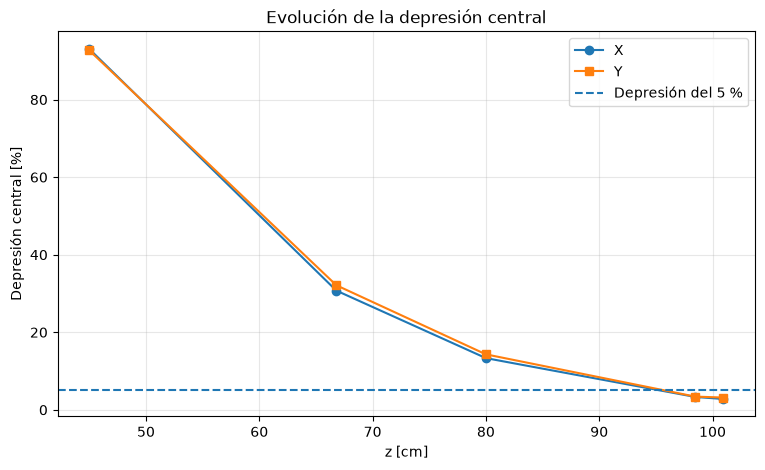

In [3]:
tabla_r = pd.DataFrame([
    {
        "z [cm]": r["z"],
        "R X": r["r_x"],
        "R Y": r["r_y"],
        "Depresión X [%]": 100 * (1 - r["r_x"]),
        "Depresión Y [%]": 100 * (1 - r["r_y"])
    }
    for r in resultados
])

display(tabla_r.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
datos_post = tabla_r[tabla_r["z [cm]"] >= 45]
ax.plot(datos_post["z [cm]"], datos_post["Depresión X [%]"], "o-", label="X")
ax.plot(datos_post["z [cm]"], datos_post["Depresión Y [%]"], "s-", label="Y")
ax.axhline(5, linestyle="--", label="Depresión del 5 %")
ax.set(xlabel="z [cm]", ylabel="Depresión central [%]", title="Evolución de la depresión central")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 5. Visualizar los perfiles originales

Aquí dibujamos los **seis perfiles** en un mosaico $2\times3$, primero en $X$ y luego en $Y$.

Cada perfil se divide por su máximo:

$$\widetilde\Phi_x(x;z_i)=\frac{\Phi_x(x;z_i)}{\max_x\Phi_x(x;z_i)}.$$

Así comparamos la **forma** de los perfiles sin que las diferencias de intensidad entre alturas oculten la depresión central. La normalización no cambia la posición de los máximos.

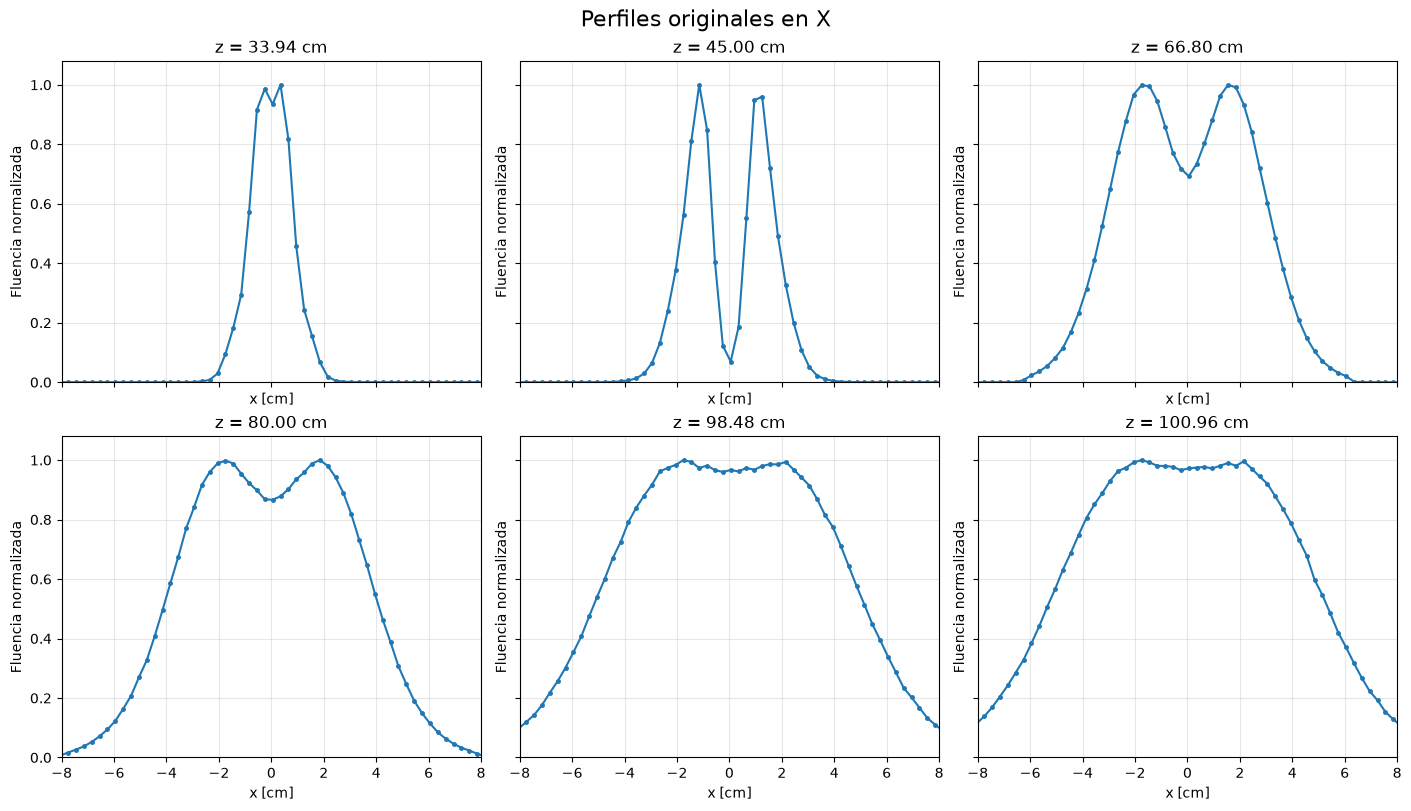

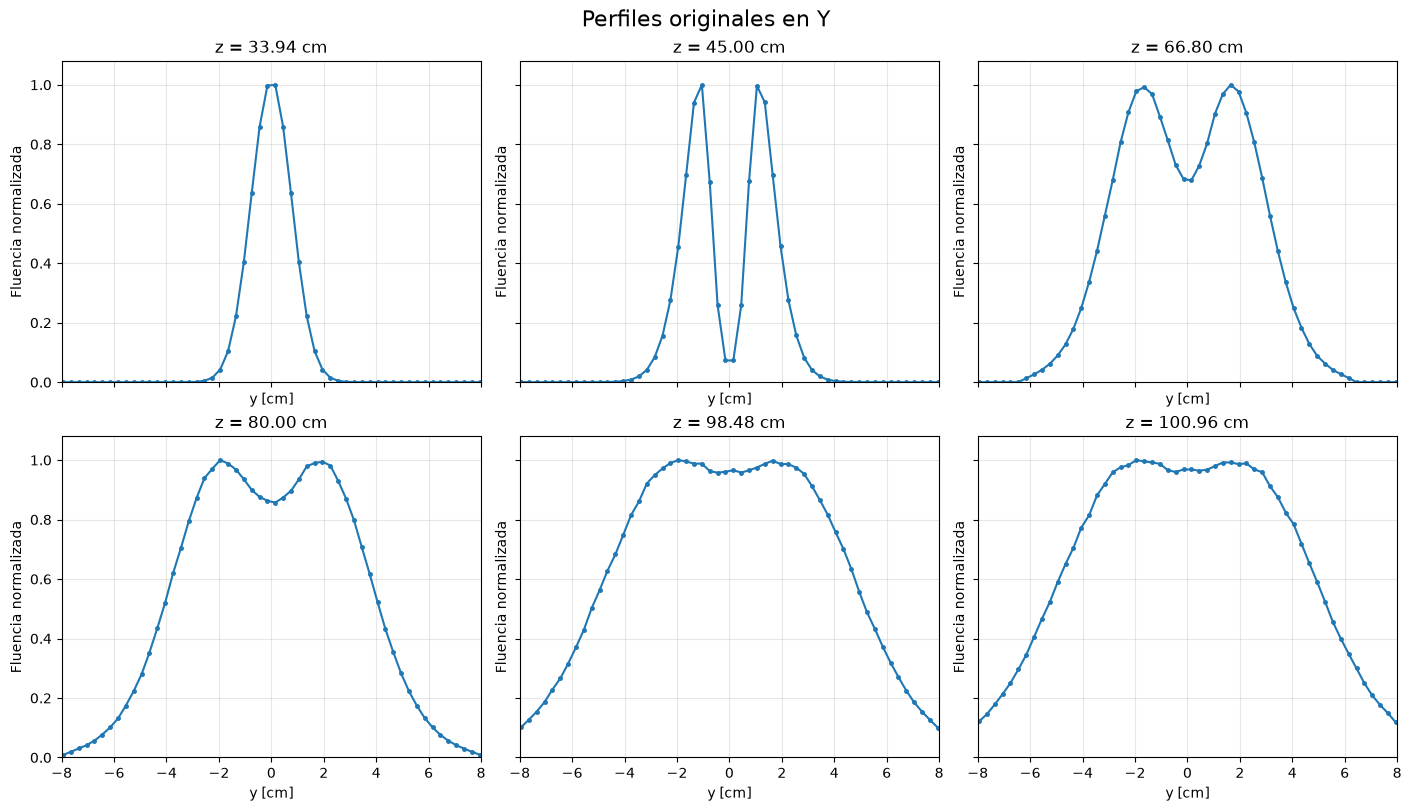

In [4]:
def mosaico_perfiles_originales(resultados, eje):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True, constrained_layout=True)
    for ax, r in zip(axes.flat, resultados):
        coord = r[eje]
        perfil = r[f"perfil_{eje}"]
        normalizado = perfil / np.max(perfil)
        ax.plot(coord, normalizado, "o-", markersize=2.5)
        ax.set_title(f"z = {r['z']:.2f} cm")
        ax.set_xlim(-8, 8)
        ax.set_ylim(0, 1.08)
        ax.set_xlabel(f"{eje} [cm]")
        ax.set_ylabel("Fluencia normalizada")
        ax.grid(alpha=0.3)
    fig.suptitle(f"Perfiles originales en {eje.upper()}", fontsize=16)
    plt.show()

mosaico_perfiles_originales(resultados, "x")
mosaico_perfiles_originales(resultados, "y")

## 6. Proponer un modelo matemático: suma de dos gaussianas

Si los dos máximos laterales son aproximadamente simétricos respecto del eje del haz, aproximamos cada perfil mediante

$$
\boxed{\Phi(u;z)=A(z)\left[\exp\left(-\frac{(u-a(z))^2}{2\sigma(z)^2}\right)+\exp\left(-\frac{(u+a(z))^2}{2\sigma(z)^2}\right)\right]+B(z),}
$$

con $u=x$ o $u=y$.

- $a(z)$: distancia desde el eje a **cada centro gaussiano**. La separación entre esos centros es $2a(z)$.
- $\sigma(z)$: ancho característico de cada componente gaussiana.
- $A(z)$: amplitud de cada componente.
- $B(z)$: fondo aproximadamente constante en el intervalo de ajuste.

**No hay que confundir** el centro de cada gaussiana ($\pm a$) con los máximos del **perfil sumado**: cuando se solapan, las posiciones de esos máximos pueden ser distintas de $\pm a$.

El oclusor es circular; por eso el mapa XY puede parecer anular. Su corte transversal es el que intentamos aproximar con esta suma de dos gaussianas, pero el ajuste no está garantizado.

In [5]:
def dos_gaussianas(u, A, a, sigma, B):
    return A * (
        np.exp(-((u - a) ** 2) / (2 * sigma ** 2))
        + np.exp(-((u + a) ** 2) / (2 * sigma ** 2))
    ) + B

## 7. Encontrar $a$ y $\sigma$ a cada altura con un ajuste

Para cada $z_i$ **posterior al oclusor**, Python busca los cuatro parámetros $(A_i,a_i,\sigma_i,B_i)$ que reproducen mejor los puntos obtenidos con PHITS.

Ajustaremos en el intervalo $-8\le u\le8\,\mathrm{cm}$ y dividiremos temporalmente el perfil por su máximo para estabilizar la optimización numérica. Luego recuperaremos $A$ y $B$ en unidades absolutas de fluencia.

Se prueban varios valores iniciales: esto disminuye el riesgo de quedar atrapados en una solución local, pero no elimina la ambigüedad de los parámetros cuando los máximos están casi fusionados.

También mediremos dos indicadores de calidad:

$$\mathrm{RMSE}=\sqrt{\frac1N\sum_i(\widetilde\Phi_i-\widetilde\Phi_{\mathrm{ajuste},i})^2},$$

$$R^2=1-\frac{\sum_i(\widetilde\Phi_i-\widetilde\Phi_{\mathrm{ajuste},i})^2}{\sum_i(\widetilde\Phi_i-\overline{\widetilde\Phi})^2}.$$

Un RMSE pequeño y un $R^2$ cercano a 1 indican que la curva global reproduce los puntos, pero **también necesitamos inspeccionar el mínimo central**, que es el detalle físico que nos interesa.

In [6]:
def ajustar_gaussianas(coord, perfil):
    mascara = (np.abs(coord) <= 8) & np.isfinite(perfil)
    u = np.asarray(coord[mascara])
    v = np.asarray(perfil[mascara])
    escala = float(np.max(v))

    if escala <= 0:
        raise ValueError("El perfil no tiene fluencia positiva")

    v_n = v / escala
    mejor = None
    mejor_rmse = np.inf

    for a0 in [0.4, 1.0, 1.5, 2.5, 3.5]:
        for sigma0 in [0.6, 1.2, 2.0, 3.5, 5.0]:
            try:
                p, _ = curve_fit(
                    dos_gaussianas,
                    u,
                    v_n,
                    p0=[0.7, a0, sigma0, 0.01],
                    bounds=([0, 0, 0.1, 0], [3, 8, 12, 0.25]),
                    maxfev=20000
                )
                pred = dos_gaussianas(u, *p)
                rmse = float(np.sqrt(np.mean((v_n - pred) ** 2)))
                if rmse < mejor_rmse:
                    mejor = p
                    mejor_rmse = rmse
            except (RuntimeError, ValueError):
                continue

    if mejor is None:
        raise RuntimeError("No se pudo ajustar el perfil")

    pred = dos_gaussianas(u, *mejor)
    ss_res = float(np.sum((v_n - pred) ** 2))
    ss_tot = float(np.sum((v_n - np.mean(v_n)) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    A_n, a, sigma, B_n = mejor

    u_fino = np.linspace(-8, 8, 1001)
    pred_fino = dos_gaussianas(u_fino, *mejor)
    R_modelo = float(dos_gaussianas(0, *mejor) / np.max(pred_fino))

    return {
        "a": float(a),
        "sigma": float(sigma),
        "A": float(A_n * escala),
        "B": float(B_n * escala),
        "A_norm": float(A_n),
        "B_norm": float(B_n),
        "escala": escala,
        "RMSE": mejor_rmse,
        "R2": r2,
        "R_modelo": R_modelo
    }


ajustes = {"x": [], "y": []}

for r in resultados:
    if r["z"] < 40:
        continue
    for eje in ("x", "y"):
        parametros = ajustar_gaussianas(r[eje], r[f"perfil_{eje}"])
        ajustes[eje].append({
            **parametros,
            "z": r["z"],
            "coord": r[eje],
            "perfil": r[f"perfil_{eje}"],
            "R_PHITS": r[f"r_{eje}"],
            "G": parametros["a"] - parametros["sigma"]
        })

print("Ajustes completados en X e Y para las cinco posiciones posteriores al oclusor")

Ajustes completados en X e Y para las cinco posiciones posteriores al oclusor


## 8. Ver los resultados del ajuste en una tabla

Esta tabla nos dice **qué valores de $a$ y $\sigma$ encontró Python en cada $z$**. La columna

$$G(z_i)=a(z_i)-\sigma(z_i)$$

será fundamental en el paso siguiente.

También comparamos $R_{\mathrm{PHITS}}$ (directo de los datos) con $R_{\mathrm{modelo}}$ (calculado a partir de las dos gaussianas ajustadas). Si ambos difieren claramente, el modelo **no reproduce adecuadamente la depresión central**, incluso si el ancho externo parece correcto.

In [7]:
tablas_ajuste = {}

for eje in ("x", "y"):
    tabla = pd.DataFrame([
        {
            "z [cm]": r["z"],
            "a [cm]": r["a"],
            "sigma [cm]": r["sigma"],
            "a-sigma [cm]": r["G"],
            "RMSE": r["RMSE"],
            "R2": r["R2"],
            "R PHITS": r["R_PHITS"],
            "R modelo": r["R_modelo"]
        }
        for r in ajustes[eje]
    ])
    tablas_ajuste[eje] = tabla
    print(f"\nParámetros ajustados — {eje.upper()}")
    display(tabla.round(4))


Parámetros ajustados — X


,z [cm],a [cm],sigma [cm],a-sigma [cm],RMSE,R2,R PHITS,R modelo
0,45.00,1.2376,0.5387,0.6990,0.0485,0.9727,0.0695,0.1541
1,66.80,1.8247,1.3049,0.5198,0.0186,0.9976,0.6926,0.7404
2,80.00,2.1458,1.7530,0.3928,0.0096,0.9993,0.8666,0.8948
3,98.48,2.5885,2.3740,0.2146,0.0054,0.9997,0.9668,0.9794
4,100.96,2.6487,2.4555,0.1932,0.0051,0.9997,0.9721,0.9842



Parámetros ajustados — Y


,z [cm],a [cm],sigma [cm],a-sigma [cm],RMSE,R2,R PHITS,R modelo
0,45.00,1.2666,0.5350,0.7316,0.0421,0.9801,0.0732,0.1311
1,66.80,1.8325,1.2886,0.5439,0.0177,0.9978,0.6787,0.7184
2,80.00,2.1554,1.7382,0.4172,0.0096,0.9993,0.8569,0.8819
3,98.48,2.5948,2.3312,0.2636,0.0055,0.9997,0.9659,0.9690
4,100.96,2.6497,2.4051,0.2446,0.0056,0.9997,0.9683,0.9746


## 9. ¿Las dos gaussianas representan bien nuestros perfiles?

Este paso **es obligatorio antes de interpretar la altura de fusión**. Dibujamos los puntos de PHITS y el ajuste en una misma figura, para las cinco alturas posteriores al oclusor.

Prestá especial atención a $z=80$, $98{,}48$ y $100{,}96\,\mathrm{cm}$: allí la depresión central es pequeña y un ajuste excelente en las alas puede, aun así, fallar en el centro.

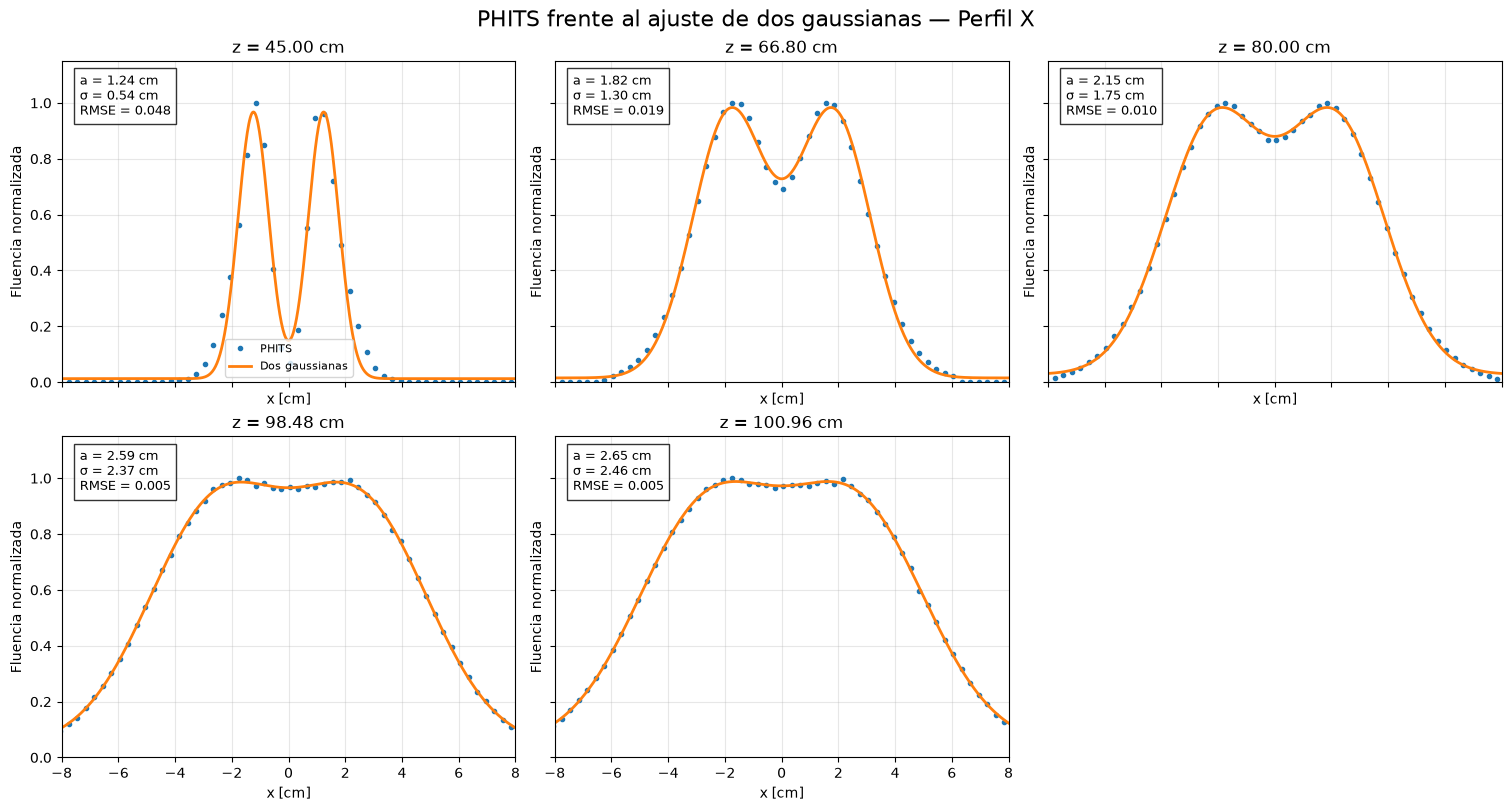

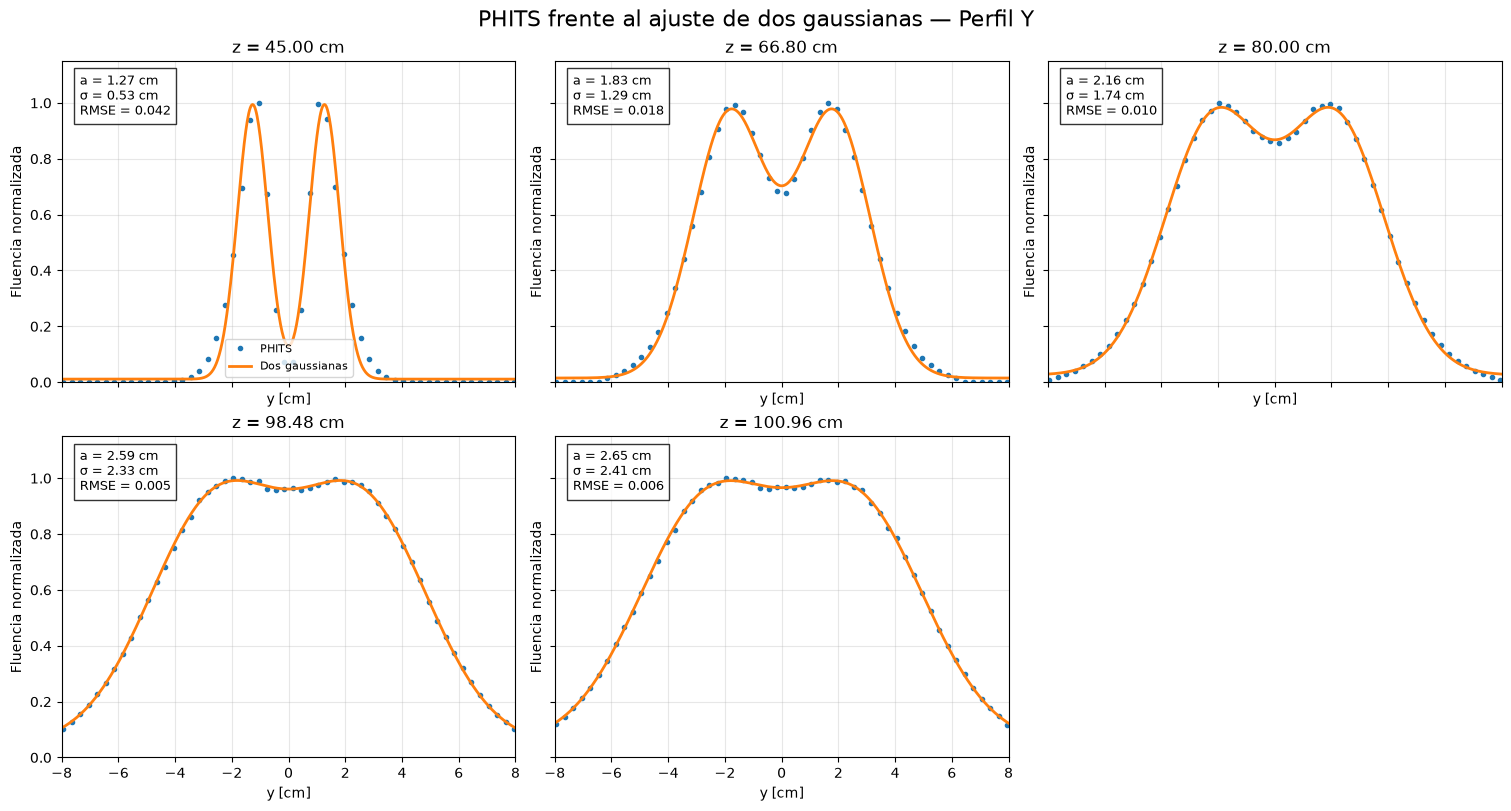

In [8]:
for eje in ("x", "y"):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True, constrained_layout=True)
    for ax, r in zip(axes.flat, ajustes[eje]):
        u_fino = np.linspace(-8, 8, 600)
        modelo = dos_gaussianas(u_fino, r["A"], r["a"], r["sigma"], r["B"])
        ax.plot(r["coord"], r["perfil"] / r["escala"], "o", markersize=3, label="PHITS")
        ax.plot(u_fino, modelo / r["escala"], "-", linewidth=2, label="Dos gaussianas")
        ax.set_title(f"z = {r['z']:.2f} cm")
        ax.set_xlim(-8, 8)
        ax.set_ylim(0, 1.15)
        ax.set_xlabel(f"{eje} [cm]")
        ax.set_ylabel("Fluencia normalizada")
        ax.grid(alpha=0.3)
        ax.text(
            0.04, 0.96,
            f"a = {r['a']:.2f} cm\nσ = {r['sigma']:.2f} cm\nRMSE = {r['RMSE']:.3f}",
            transform=ax.transAxes,
            va="top",
            fontsize=9,
            bbox=dict(facecolor="white", alpha=0.8)
        )
    axes.flat[-1].axis("off")
    axes.flat[0].legend(loc="lower center", fontsize=8)
    fig.suptitle(f"PHITS frente al ajuste de dos gaussianas — Perfil {eje.upper()}", fontsize=16)
    plt.show()

## 10. Demostración de la condición matemática $a=\sigma$

Queremos saber cuándo el **mínimo central deja de ser un mínimo**. Para un perfil simétrico, la primera derivada en $u=0$ es cero; por eso examinamos la segunda derivada.

Partimos de

$$\Phi(u)=A\left[e^{-(u-a)^2/(2\sigma^2)}+e^{-(u+a)^2/(2\sigma^2)}\right]+B.$$

Su curvatura en el centro es

$$
\boxed{\left.\frac{\partial^2\Phi}{\partial u^2}\right|_{u=0}
=\frac{2A}{\sigma^4}\,e^{-a^2/(2\sigma^2)}\,(a^2-\sigma^2).}
$$

Como $A>0$ y $\sigma>0$, el signo depende únicamente de $a^2-\sigma^2$:

| Condición | Curvatura central | Forma del perfil sumado |
|---|---|---|
| $a>\sigma$ | Positiva | Mínimo central, dos máximos laterales |
| $a=\sigma$ | Nula | Transición entre ambas formas |
| $a<\sigma$ | Negativa | Máximo central |

Por lo tanto, para **este modelo**:

$$\boxed{z_*:\quad G(z_*)=a(z_*)-\sigma(z_*)=0.}$$

No hay que confundir $z_*$ con la altura en la que la depresión se vuelve menor al 5 %: esa es otra condición y puede alcanzarse mucho antes.

## 11. Interpolar los parámetros solo en el intervalo simulado

Se mantiene la interpolación PCHIP para los cinco planos de PHITS con $45\le z\le100{,}96$ cm.

Fuera de ese rango no se utiliza PCHIP, porque extrapolar el último tramo cúbico puede producir valores no físicos. Más abajo se define una función **independiente** para explorar posiciones mayores con extrapolación lineal de $a$ y $\sigma$.


In [9]:
interpoladores = {}

for eje in ("x", "y"):
    datos = ajustes[eje]
    z = np.array([r["z"] for r in datos])
    interpoladores[eje] = {
        "zmin": float(z.min()),
        "zmax": float(z.max()),
        "a": PchipInterpolator(z, [r["a"] for r in datos]),
        "sigma": PchipInterpolator(z, [r["sigma"] for r in datos]),
        "A": PchipInterpolator(z, [r["A"] for r in datos]),
        "B": PchipInterpolator(z, [r["B"] for r in datos])
    }


def perfil_modelado(u, z, eje="x"):
    f = interpoladores[eje]
    if not f["zmin"] <= z <= f["zmax"]:
        raise ValueError(f"z debe estar entre {f['zmin']} y {f['zmax']} cm; para alturas mayores usar perfil_extrapolado")
    return dos_gaussianas(
        np.asarray(u),
        float(f["A"](z)),
        float(f["a"](z)),
        float(f["sigma"](z)),
        float(f["B"](z))
    )


## 12. Buscar la altura donde se cumple $a(z)=\sigma(z)$

Construimos

$$G(z)=a(z)-\sigma(z)$$

y buscamos las raíces de $G(z)=0$ **dentro de las alturas medidas**. Utilizamos `brentq` en los intervalos donde se observa un cambio de signo.

Si no se encuentra ningún cruce antes del piso, el mensaje será **«No se encontró transición dentro del intervalo simulado»**. No extrapolaremos automáticamente: más allá del último plano no hay datos que validen la forma de $a(z)$ y $\sigma(z)$.

Si el ajuste de los perfiles fuera deficiente, una raíz obtenida en esta etapa **no sería una estimación física fiable**.

X: no se encontró a = σ entre 45.00 y 100.96 cm
Y: no se encontró a = σ entre 45.00 y 100.96 cm


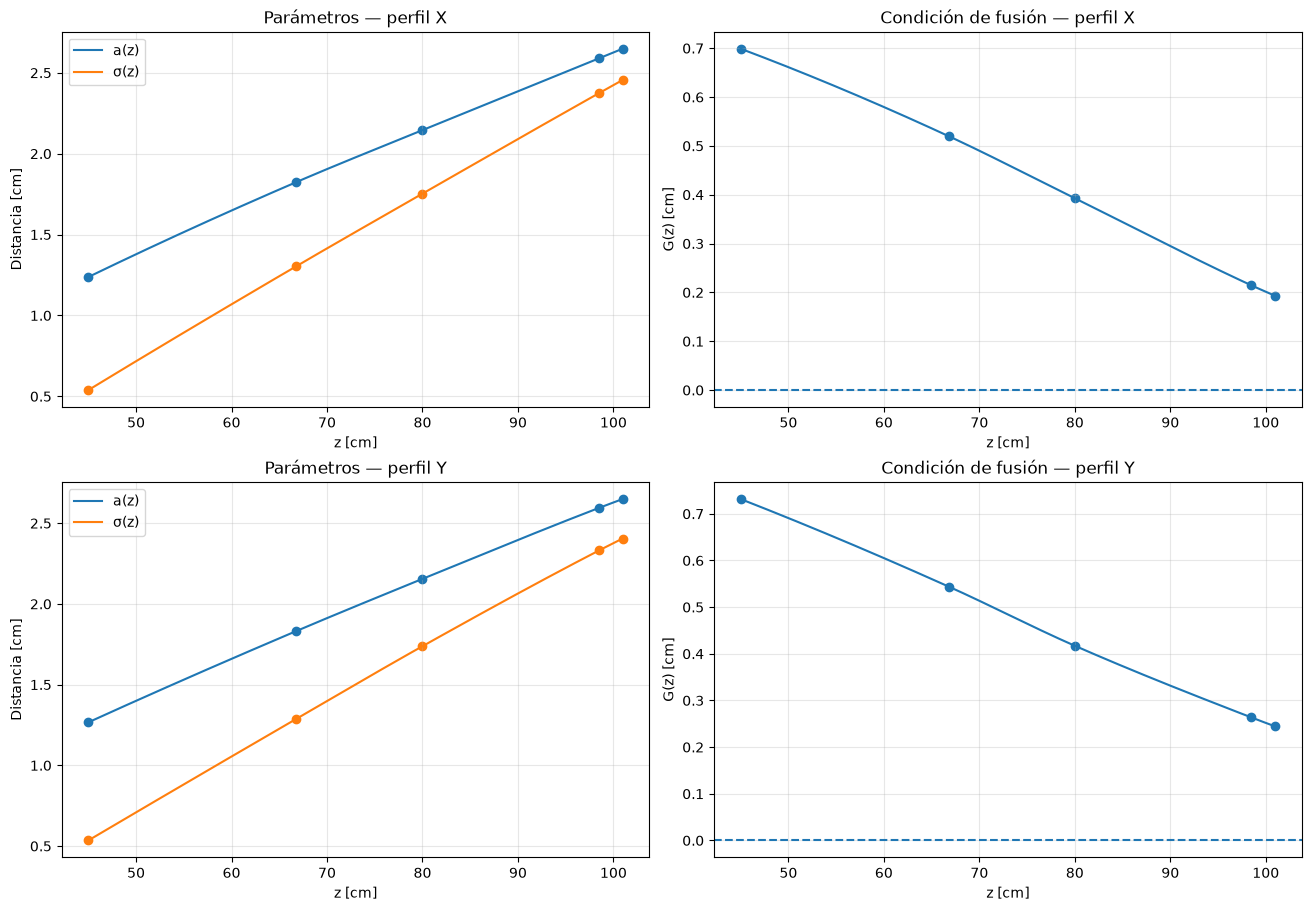

In [10]:
raices = {"x": [], "y": []}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

for fila, eje in enumerate(("x", "y")):
    datos = ajustes[eje]
    f = interpoladores[eje]
    z_datos = np.array([r["z"] for r in datos])
    a_datos = np.array([r["a"] for r in datos])
    sigma_datos = np.array([r["sigma"] for r in datos])
    z_suave = np.linspace(f["zmin"], f["zmax"], 2000)
    a_suave = f["a"](z_suave)
    sigma_suave = f["sigma"](z_suave)
    G_suave = a_suave - sigma_suave

    ax1 = axes[fila, 0]
    ax1.plot(z_suave, a_suave, label="a(z)")
    ax1.plot(z_suave, sigma_suave, label="σ(z)")
    ax1.scatter(z_datos, a_datos)
    ax1.scatter(z_datos, sigma_datos)
    ax1.set(xlabel="z [cm]", ylabel="Distancia [cm]", title=f"Parámetros — perfil {eje.upper()}")
    ax1.grid(alpha=0.3)
    ax1.legend()

    ax2 = axes[fila, 1]
    ax2.plot(z_suave, G_suave, label="G(z) = a(z) - σ(z)")
    ax2.scatter(z_datos, a_datos - sigma_datos)
    ax2.axhline(0, linestyle="--")
    ax2.set(xlabel="z [cm]", ylabel="G(z) [cm]", title=f"Condición de fusión — perfil {eje.upper()}")
    ax2.grid(alpha=0.3)

    for i in range(len(z_suave) - 1):
        g1, g2 = G_suave[i], G_suave[i + 1]
        if g1 * g2 < 0:
            raiz = brentq(lambda zz: float(f["a"](zz) - f["sigma"](zz)), z_suave[i], z_suave[i + 1])
            if not raices[eje] or abs(raiz - raices[eje][-1]) > 1e-3:
                raices[eje].append(float(raiz))
                ax2.axvline(raiz, linestyle=":", label=f"z* = {raiz:.2f} cm")

    if raices[eje]:
        ax2.legend()
        print(f"{eje.upper()}: z* estimado = " + ", ".join(f"{v:.3f} cm" for v in raices[eje]))
    else:
        print(f"{eje.upper()}: no se encontró a = σ entre {f['zmin']:.2f} y {f['zmax']:.2f} cm")

plt.show()

## 13. Verificar la curvatura central sin imponer dos gaussianas

El criterio anterior depende del ajuste completo de dos gaussianas. Como **verificación independiente**, estimamos la curvatura directamente de los datos de PHITS cerca del centro.

Para cada altura aproximamos los puntos cercanos al origen por un polinomio de segundo grado:

$$\widetilde\Phi(u,z_i)\simeq c_0+c_1u+c_2u^2.$$

Entonces

$$\left.\frac{\partial^2\widetilde\Phi}{\partial u^2}\right|_{u=0}\simeq2c_2.$$

- $2c_2>0$: tendencia local a un mínimo en el centro.
- $2c_2<0$: tendencia local a un máximo en el centro.
- $2c_2\approx0$: perfil casi plano; la incertidumbre numérica importa mucho.

Usaremos, inicialmente, los bins dentro de $\pm1{,}5\,\mathrm{cm}$. **El resultado depende de esa ventana y del ruido Monte Carlo**, por lo que no debe interpretarse como una demostración definitiva sin un análisis de sensibilidad e incertidumbre.

,z [cm],Curvatura X [cm^-2],Curvatura Y [cm^-2]
0,45.00,0.89118,0.99294
1,66.80,0.30189,0.31767
2,80.00,0.11520,0.12575
3,98.48,0.02331,0.03326
4,100.96,0.01514,0.03242


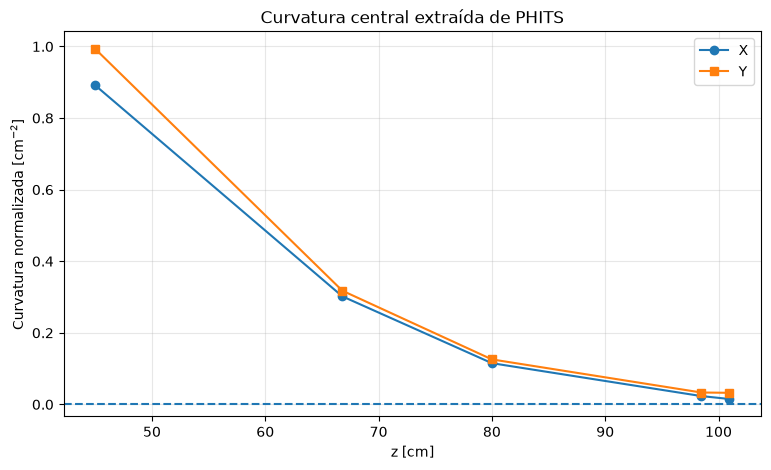

In [11]:
def curvatura_central(coord, perfil, semiancho=1.5):
    mascara = np.abs(coord) <= semiancho
    u = np.asarray(coord[mascara])
    v = np.asarray(perfil[mascara])
    v = v / np.max(perfil)
    if len(u) < 4:
        raise ValueError("Hay muy pocos bins en el intervalo central")
    c2, c1, c0 = np.polyfit(u, v, deg=2)
    return float(2 * c2)

filas_curvatura = []

for r in resultados:
    if r["z"] < 40:
        continue
    filas_curvatura.append({
        "z [cm]": r["z"],
        "Curvatura X [cm^-2]": curvatura_central(r["x"], r["perfil_x"]),
        "Curvatura Y [cm^-2]": curvatura_central(r["y"], r["perfil_y"])
    })

tabla_curvatura = pd.DataFrame(filas_curvatura)
display(tabla_curvatura.round(5))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_curvatura["z [cm]"], tabla_curvatura["Curvatura X [cm^-2]"], "o-", label="X")
ax.plot(tabla_curvatura["z [cm]"], tabla_curvatura["Curvatura Y [cm^-2]"], "s-", label="Y")
ax.axhline(0, linestyle="--")
ax.set(xlabel="z [cm]", ylabel="Curvatura normalizada [cm$^{-2}$]", title="Curvatura central extraída de PHITS")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 14. Comparar con otro criterio: depresión central menor al 5 %

Para decidir una posición práctica de irradiación también puede ser útil solicitar

$$D(z)\le5\%\quad\Longleftrightarrow\quad R(z)\ge0{,}95.$$

Esto **no es lo mismo que** $a(z)=\sigma(z)$: una depresión central del 4 % sigue correspondiendo a un mínimo central si la curvatura continúa siendo positiva.

Con los valores que compartimos antes, la interpolación lineal entre $z=80$ y $z=98{,}48\,\mathrm{cm}$ predice un umbral cercano a $95{,}3$–$95{,}8\,\mathrm{cm}$ para $X$ e $Y$. El siguiente código recalcula ese número utilizando los datos de los archivos actuales.

In [12]:
def primera_altura_umbral(resultados, eje="x", umbral=0.95):
    pares = [(r["z"], r[f"r_{eje}"]) for r in resultados if r["z"] >= 45]
    for (z1, r1), (z2, r2) in zip(pares[:-1], pares[1:]):
        if r1 < umbral <= r2:
            return float(z1 + (umbral - r1) * (z2 - z1) / (r2 - r1))
    return None

for eje in ("x", "y"):
    z95 = primera_altura_umbral(resultados, eje=eje)
    if z95 is None:
        print(f"{eje.upper()}: no se encontró cruce ascendente de R = 0.95")
    else:
        print(f"{eje.upper()}: primera altura estimada con R >= 0.95: z ≈ {z95:.2f} cm")

X: primera altura estimada con R >= 0.95: z ≈ 95.38 cm
Y: primera altura estimada con R >= 0.95: z ≈ 95.78 cm


## 15. Extrapolación controlada de los perfiles para 110 y 120 cm

La extrapolación cúbica PCHIP **fuera** del intervalo de PHITS puede generar deformaciones. Usamos una extrapolación **lineal** de $a(z)$ y $\sigma(z)$ ajustada a los tres planos finales ($80$, $98{,}48$ y $100{,}96$ cm), siguiendo la misma idea empleada para estimar la fusión $a=\sigma$.

Para mostrar la **fluencia absoluta**, las amplitudes positivas $A(z)$ y $B(z)$ se extrapolan linealmente en su logaritmo (evita amplitudes negativas). Si algún valor de $B$ es cero, se mantiene su último valor sin extrapolarlo. Esta elección **no está validada con PHITS** y el valor absoluto debe interpretarse con cautela; la evolución de la forma depende principalmente de $a$ y $\sigma$.

En cada gráfico se informa la depresión central $100\,[1-\Phi(0)/\max\Phi]$ para facilitar la comparación.


z=110.0 cm, X: a=2.8652 cm, sigma=2.7595 cm, a-sigma=0.1056 cm, depresión=0.39%
z=110.0 cm, Y: a=2.8653 cm, sigma=2.6961 cm, a-sigma=0.1692 cm, depresión=1.00%
z=120.0 cm, X: a=3.1050 cm, sigma=3.0950 cm, a-sigma=0.0100 cm, depresión=0.00%
z=120.0 cm, Y: a=3.1019 cm, sigma=3.0153 cm, a-sigma=0.0866 cm, depresión=0.21%


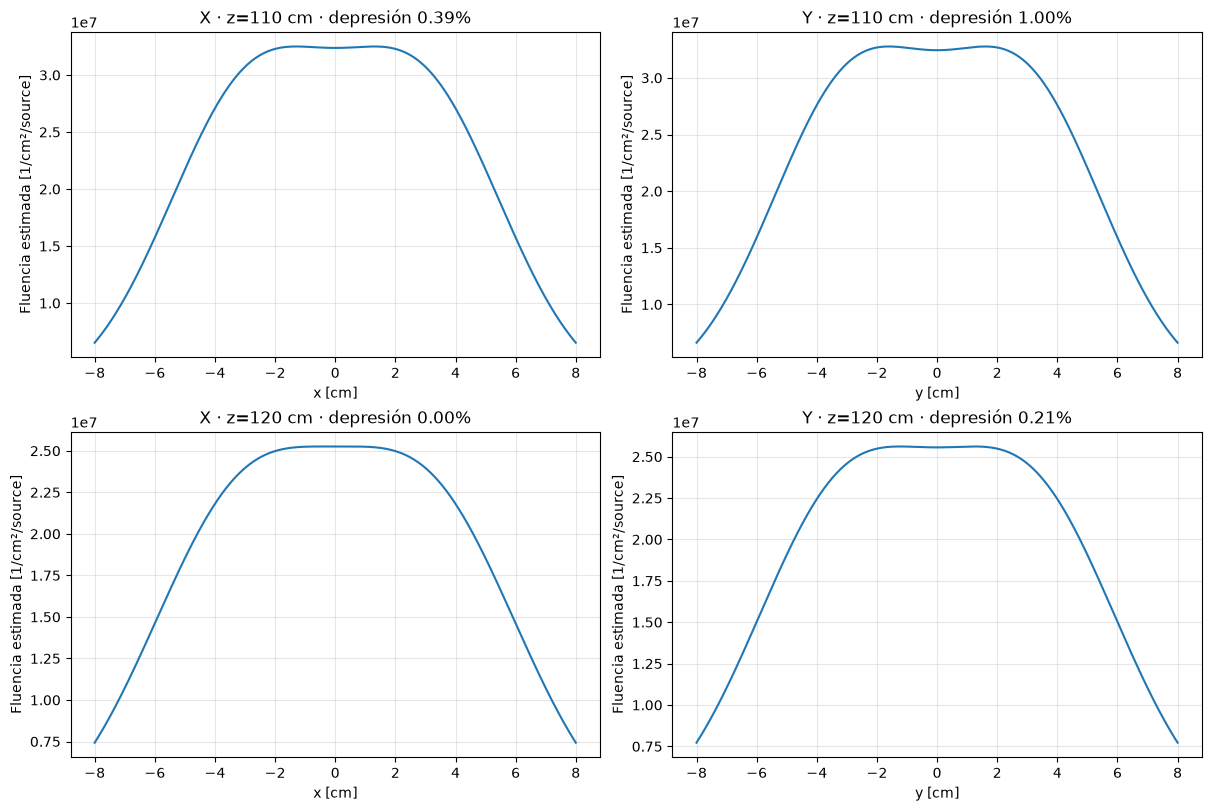

In [13]:
def parametros_extrapolados(eje, z):
    f = interpoladores[eje]
    if f["zmin"] <= z <= f["zmax"]:
        return {k: float(f[k](z)) for k in ("A", "a", "sigma", "B")}
    if z < f["zmin"]:
        raise ValueError("La extrapolación está definida solo hacia posiciones posteriores al último T-Track")

    ultimos = ajustes[eje][-3:]
    alturas = np.array([r["z"] for r in ultimos], dtype=float)
    parametros = {}

    for nombre in ("a", "sigma"):
        valores = np.array([r[nombre] for r in ultimos], dtype=float)
        pendiente, ordenada = np.polyfit(alturas, valores, 1)
        parametros[nombre] = float(pendiente * z + ordenada)

    for nombre in ("A", "B"):
        valores = np.array([r[nombre] for r in ultimos], dtype=float)
        if np.all(valores > 0):
            pendiente, ordenada = np.polyfit(alturas, np.log(valores), 1)
            parametros[nombre] = float(np.exp(pendiente * z + ordenada))
        elif nombre == "B":
            parametros[nombre] = max(0.0, float(valores[-1]))
        else:
            raise ValueError("Los valores de A no permiten extrapolación log-lineal")

    if parametros["a"] < 0 or parametros["sigma"] <= 0:
        raise ValueError(f"Los parámetros extrapolados en {z} cm dejaron de ser físicos")
    return parametros


def perfil_extrapolado(u, z, eje="x"):
    p = parametros_extrapolados(eje, z)
    return dos_gaussianas(np.asarray(u), p["A"], p["a"], p["sigma"], p["B"])


u = np.linspace(-8, 8, 600)
alturas_a_mostrar = [110.0, 120.0]
fig, axes = plt.subplots(len(alturas_a_mostrar), 2, figsize=(12, 8), constrained_layout=True)

for fila, z_prueba in enumerate(alturas_a_mostrar):
    for columna, eje in enumerate(("x", "y")):
        p = parametros_extrapolados(eje, z_prueba)
        pred = perfil_extrapolado(u, z_prueba, eje=eje)
        centro = float(perfil_extrapolado(np.array([0.0]), z_prueba, eje=eje)[0])
        depresion = 100 * (1 - centro / np.max(pred))
        print(f"z={z_prueba:.1f} cm, {eje.upper()}: a={p['a']:.4f} cm, sigma={p['sigma']:.4f} cm, a-sigma={p['a']-p['sigma']:.4f} cm, depresión={depresion:.2f}%")
        ax = axes[fila, columna]
        ax.plot(u, pred)
        ax.set(xlabel=f"{eje} [cm]", ylabel="Fluencia estimada [1/cm²/source]", title=f"{eje.upper()} · z={z_prueba:.0f} cm · depresión {depresion:.2f}%")
        ax.grid(alpha=0.3)

plt.show()


## 16. ¿Qué podemos concluir científicamente?

**Hay que distinguir tres conceptos:**

| Pregunta | Cantidad usada | Qué permite concluir |
|---|---|---|
| ¿La sombra central se redujo mucho? | $D(z)=100[1-R(z)]$ | Cuánto más débil es el centro respecto del máximo |
| ¿Desapareció matemáticamente el mínimo central? | $a(z)=\sigma(z)$, **si el modelo ajusta bien**, o cambio de signo de la curvatura | Transición entre dos máximos y uno central |
| ¿El campo es homogéneo sobre el pouch? | Coeficiente de variación sobre su **área XY real** | Uniformidad sobre la muestra completa |

### Interpretación para nuestras simulaciones

- Después del oclusor ($z=45\,\mathrm{cm}$), la depresión central es muy pronunciada.
- A medida que aumenta $z$, la sombra se rellena y el haz se ensancha.
- En los datos que compartimos, a $z=98{,}48\,\mathrm{cm}$ la depresión central es cercana al 3,3 %, pero todavía podrían distinguirse dos máximos laterales.
- El cálculo de $z_*$ solo es válido si las curvas ajustadas reproducen ese comportamiento central. Si el ajuste predice una transición pero PHITS aún muestra un mínimo claro, **no debemos aceptar ese $z_*$ sin más comprobaciones**.
- La muestra real no es aire. Una vez elegida una altura candidata, deben revisarse el espectro energético y la **dosis en la geometría con pouch/agua**, ya que los perfiles en aire no son equivalentes a los del material irradiado.

### Limitaciones y próximos controles

1. La malla actual es de 3 mm por bin. Una depresión de apenas unos puntos porcentuales puede requerir **bins más finos** y mejor estadística para identificar con precisión la curvatura.
2. Sería conveniente incluir nuevos planos de PHITS cerca de cualquier transición estimada; por ejemplo, entre 90 y 101 cm si el modelo la ubica allí.
3. La incertidumbre del ajuste y el ruido Monte Carlo no se convirtieron aquí en una incertidumbre formal de $z_*$. El cruce obtenido es, por lo tanto, **exploratorio**.
4. Una mejor homogeneidad de la fluencia **no demuestra** automáticamente una mejor homogeneidad de la dosis en el pouch.

**Conclusión metodológica:** primero comprobamos que el ajuste de dos gaussianas es físicamente razonable; solo entonces calculamos dónde $a(z)=\sigma(z)$. De forma paralela, usamos el umbral práctico de depresión central y, finalmente, evaluamos la homogeneidad y la dosis en la región real del pouch.